# 1. Does pre-stimulus behaviour predict the upcoming trial, and does the NM add to it?

Independent of any latent-state model. Per trial, over the second before stimulus onset (clipped at trial start, as the photometry masks are):
- **motor**: mean log(1 + |x|) of paw speed, wheel speed, whisker ME and lick rate, plus *quiescence resets* (how long the trial waited beyond its sampled quiescence period because the wheel moved; log).
- **NM**: pre-stimulus baseline (same samples) and stimulus response (0.1–0.4 s after stimulus onset).
- **task**: |contrast| level, block congruence, previous outcome, previous-choice congruence (stimulus on the side chosen last trial), trial position (+ squared).

Three questions, each a cross-validated nested model within session (within fiber for the NM):
- **a. motor → outcome**: does motor state add to the task variables in predicting accuracy (logistic; Δ held-out log-likelihood, bits/trial) and log RT (first movement; ridge ΔR²)?
- **b. NM → outcome, beyond motor**: does the NM baseline add to task + motor (and to task alone)?
- **c. motor → NM stimulus response**: does pre-stimulus motor state change the stimulus response, with task, log response RT, choice side and the NM baseline held fixed?

**Null.** The added predictors are rotated across the session's trials (circular shift, 50 times), which keeps their slow drift. *Excess* = gain − mean null gain: what the predictors add at the trial-by-trial level, beyond slow co-drift with the outcome. Mice are the unit (mean over sessions/fibers, then across mice). Functions and cache: `prestim.py`.

In [1]:
import sys, pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'Functions' / 'nm_syllables.py').exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO)); sys.path.insert(0, str(REPO / 'neuromodulators' / 'behavioural_states'))
import prestim as pp
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)

if not (pp.OUT / f'gains_{pp.ns.RUN}.pkl').exists():
    pp.run()
G, C = pp.load()
NM_ORDER = ['DR-5HT', 'VTA-DA', 'SNc-DA', 'LC-NE', 'NBM-ACh']
NM_COLORS = dict(zip(NM_ORDER, ['#CC79A7', '#E69F00', '#D55E00', '#0072B2', '#009E73']))
cov = G.groupby('target_NM').agg(mice=('subject', 'nunique'), sessions=('eid', 'nunique'),
                                 fibers=('region', lambda r: len(set(zip(G.loc[r.index, 'eid'], r)))))
cov.loc[NM_ORDER]

,mice,sessions,fibers
target_NM,,,
DR-5HT,9,140,140
VTA-DA,7,138,138
SNc-DA,6,65,65
LC-NE,8,96,96
NBM-ACh,7,50,75


## a. Motor state → outcome

Left: per mouse, the excess gain (null-corrected) of adding motor to task. Right: per session, z of the gain against its own null; |z| > 2 marks sessions where motor clearly predicts beyond slow drift.

,question,outcome,mice,mean excess,positive,p
0,a. motor | task,correct,37,0.0007,26/37,0.3968
1,a. motor | task,log RT,37,0.0332,35/37,0.0000


sessions with z > 2: {'correct': '7% of 487', 'log RT': '68% of 487'}


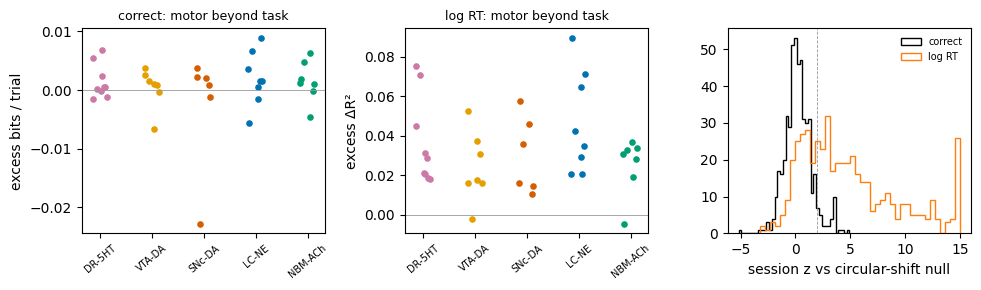

In [2]:
A = G[G['question'] == 'a. motor | task']
tab, mice = pp.by_mouse(A)
display(tab.round(4))
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, (o, unit) in zip(axes[:2], [('correct', 'bits / trial'), ('log RT', 'ΔR²')]):
    m = mice[mice['outcome'] == o]
    for i, nm in enumerate(NM_ORDER):
        v = m[m['target_NM'] == nm]['excess']
        ax.scatter(np.full(len(v), i) + np.random.default_rng(0).uniform(-.15, .15, len(v)), v, s=14,
                   color=NM_COLORS[nm])
    ax.axhline(0, c='0.6', lw=0.6)
    ax.set_xticks(range(len(NM_ORDER)), NM_ORDER, rotation=40, fontsize=7)
    ax.set_title(f'{o}: motor beyond task', fontsize=9); ax.set_ylabel(f'excess {unit}')
ax = axes[2]
for o, c in [('correct', 'k'), ('log RT', 'C1')]:
    ax.hist(A.loc[A['outcome'] == o, 'z'].clip(-6, 15), bins=40, histtype='step', color=c, label=o)
ax.axvline(2, c='0.6', ls='--', lw=0.6); ax.set_xlabel('session z vs circular-shift null'); ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
print('sessions with z > 2:', A.groupby('outcome')['z'].apply(lambda z: f'{(z > 2).mean():.0%} of {len(z)}').to_dict())

### Which motor features, in which direction?

Standardised coefficients of the full model (task + motor + NM baseline, all trials), mouse means. For accuracy, positive = more of it before the stimulus → more likely correct. For log RT, positive = slower.

,outcome,mean,sem,positive,mice
paw speed,correct,-0.019,0.011,14,36
wheel speed,correct,0.031,0.012,24,36
whisker ME,correct,-0.016,0.012,13,36
lick rate,correct,0.038,0.008,31,36
quiescence resets,correct,-0.017,0.009,13,36
NM baseline,correct,-0.035,0.017,14,36
paw speed,log RT,-0.000,0.017,22,36
wheel speed,log RT,-0.013,0.010,14,36
whisker ME,log RT,0.142,0.023,30,36
lick rate,log RT,-0.030,0.007,6,36


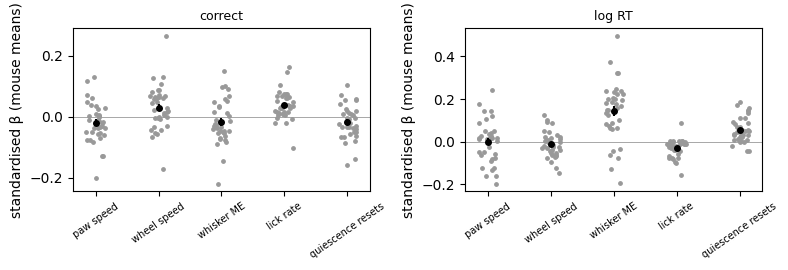

In [3]:
rows = []
for o in ['correct', 'log RT']:
    c = C[C['outcome'] == o].groupby('subject')[pp.MOTOR + ['NM baseline']].mean()
    rows.append(pd.DataFrame({'outcome': o, 'mean': c.mean(), 'sem': c.sem(), 'positive': (c > 0).sum(),
                              'mice': c.notna().sum()}))
coef_tab = pd.concat(rows)
display(coef_tab.round(3))
fig, axes = plt.subplots(1, 2, figsize=(8, 2.8), sharey=False)
for ax, o in zip(axes, ['correct', 'log RT']):
    c = C[C['outcome'] == o].groupby('subject')[pp.MOTOR].mean()
    for j, f in enumerate(pp.MOTOR):
        ax.scatter(np.full(len(c), j) + np.random.default_rng(j).uniform(-.15, .15, len(c)), c[f], s=6, color='0.6')
        ax.errorbar(j, c[f].mean(), c[f].sem(), fmt='o', color='k', ms=4)
    ax.axhline(0, c='0.6', lw=0.6)
    ax.set_xticks(range(len(pp.MOTOR)), pp.MOTOR, rotation=35, fontsize=7)
    ax.set_title(o, fontsize=9); ax.set_ylabel('standardised β (mouse means)')
fig.tight_layout()

## b. Does the NM baseline predict the outcome beyond motor state?

Per NM: excess gain of the pre-stimulus NM baseline over task alone and over task + motor, and the direction (β of the baseline in the full model).

mice  mean excess positive       p
outcome target_NM question                                                
correct DR-5HT    b. NM | task             9       0.0002      4/9  0.5407
                  b. NM | task + motor     9       0.0005      6/9  0.1993
        LC-NE     b. NM | task             8       0.0005      6/8  0.6063
                  b. NM | task + motor     8       0.0009      6/8  0.4472
        NBM-ACh   b. NM | task             7       0.0007      6/7  0.1203
                  b. NM | task + motor     7       0.0010      5/7  0.3037
        SNc-DA    b. NM | task             6       0.0009      5/6  0.0563
                  b. NM | task + motor     6       0.0012      5/6  0.1213
        VTA-DA    b. NM | task             7       0.0023      5/7  0.0318
                  b. NM | task + motor     7       0.0023      5/7  0.0226
log RT  DR-5HT    b. NM | task             9       0.0038      7/9  0.0616
                  b. NM | task + motor     9       0.0024      9/9  0.0169
        LC-NE     b. NM | task             8       0.0028      6/8  0.0803
                  b. NM | task + motor     8       0.0020      7/8  0.0039
        NBM-ACh   b. NM | task             7       0.0071      6/7  0.0688
                  b. NM | task + motor     7       0.0031      6/7  0.0990
        SNc-DA    b. NM | task             6       0.0068      6/6  0.0508
                  b. NM | task + motor     6       0.0102      6/6  0.0445
        VTA-DA    b. NM | task             7       0.0048      6/7  0.0551
                  b. NM | task + motor     7       0.0059      7/7  0.0076

mean    sem positive
outcome target_NM                       
correct DR-5HT     0.023  0.018      6/9
        LC-NE      0.057  0.028      6/8
        NBM-ACh   -0.055  0.031      2/7
        SNc-DA    -0.107  0.020      0/6
        VTA-DA    -0.140  0.022      0/7
log RT  DR-5HT    -0.028  0.009      0/9
        LC-NE     -0.010  0.016      3/8
        NBM-ACh    0.037  0.019      6/7
        SNc-DA     0.082  0.017      6/6
        VTA-DA     0.076  0.017      7/7

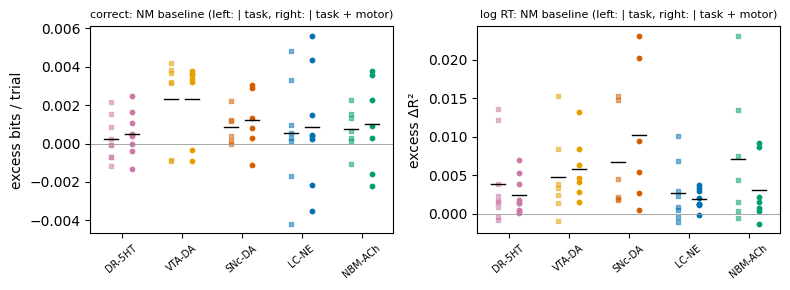

In [4]:
B = G[G['question'].str.startswith('b.')]
tab, mice_b = pp.by_mouse(B, group=('question', 'outcome', 'target_NM'))
display(tab.set_index(['outcome', 'target_NM', 'question']).sort_index().round(4))
beta = (C[C['outcome'] != 'NM response'].groupby(['outcome', 'target_NM', 'subject'])['NM baseline'].mean().groupby(['outcome', 'target_NM'])
        .agg(['mean', 'sem', lambda x: f"{(x > 0).sum()}/{len(x)}"]).rename(columns={'<lambda_0>': 'positive'}))
display(beta.round(3))

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, (o, unit) in zip(axes, [('correct', 'bits / trial'), ('log RT', 'ΔR²')]):
    for k, q in enumerate(['b. NM | task', 'b. NM | task + motor']):
        m = mice_b[(mice_b['outcome'] == o) & (mice_b['question'] == q)]
        for i, nm in enumerate(NM_ORDER):
            v = m[m['target_NM'] == nm]['excess']
            x = i + (k - 0.5) * 0.35
            ax.scatter(np.full(len(v), x), v, s=10, color=NM_COLORS[nm], alpha=0.5 if k == 0 else 1,
                       marker='o' if k else 's')
            ax.plot([x - .12, x + .12], [v.mean()] * 2, c='k', lw=1)
    ax.axhline(0, c='0.6', lw=0.6)
    ax.set_xticks(range(len(NM_ORDER)), NM_ORDER, rotation=40, fontsize=7)
    ax.set_title(f'{o}: NM baseline (left: | task, right: | task + motor)', fontsize=8); ax.set_ylabel(f'excess {unit}')
fig.tight_layout()

## c. Does pre-stimulus motor state change the NM stimulus response?

Per NM: excess ΔR² of motor over task (+ log response RT, choice side, NM baseline) for the mean response 0.1–0.4 s after stimulus onset, and the direction per motor feature.

,question,mice,mean excess,positive,p
target_NM,,,,,
DR-5HT,c. motor | task,9,0.0277,9/9,0.0025
VTA-DA,c. motor | task,7,0.0098,6/7,0.0287
SNc-DA,c. motor | task,6,0.0119,6/6,0.0025
LC-NE,c. motor | task,8,0.0337,6/8,0.1208
NBM-ACh,c. motor | task,7,0.0234,7/7,0.0324


,paw speed,wheel speed,whisker ME,lick rate,quiescence resets
target_NM,,,,,
DR-5HT,-0.035,-0.024,-0.002,0.012,-0.010
VTA-DA,-0.005,0.057,-0.002,-0.009,-0.022
SNc-DA,-0.031,0.030,-0.001,0.000,0.053
LC-NE,-0.033,-0.034,-0.043,0.003,0.011
NBM-ACh,0.009,-0.038,-0.015,-0.000,-0.004


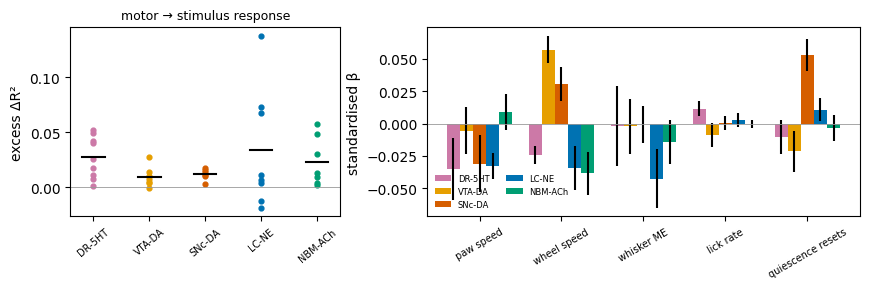

In [5]:
Cq = G[G['question'] == 'c. motor | task']
tab, mice_c = pp.by_mouse(Cq, group=('question', 'target_NM'))
display(tab.set_index('target_NM').loc[NM_ORDER].round(4))
cc = C[C['outcome'] == 'NM response'].groupby(['target_NM', 'subject'])[pp.MOTOR].mean()
display(cc.groupby('target_NM').mean().loc[NM_ORDER].round(3))
fig, axes = plt.subplots(1, 2, figsize=(9, 3), gridspec_kw={'width_ratios': [1, 1.6]})
ax = axes[0]
for i, nm in enumerate(NM_ORDER):
    v = mice_c[mice_c['target_NM'] == nm]['excess']
    ax.scatter(np.full(len(v), i), v, s=12, color=NM_COLORS[nm]); ax.plot([i - .2, i + .2], [v.mean()] * 2, c='k')
ax.axhline(0, c='0.6', lw=0.6); ax.set_xticks(range(len(NM_ORDER)), NM_ORDER, rotation=40, fontsize=7)
ax.set_ylabel('excess ΔR²'); ax.set_title('motor → stimulus response', fontsize=9)
ax = axes[1]
w = 0.16
for i, nm in enumerate(NM_ORDER):
    c = cc.loc[nm]
    ax.bar(np.arange(len(pp.MOTOR)) + (i - 2) * w, c.mean(), w, yerr=c.sem(), color=NM_COLORS[nm], label=nm)
ax.axhline(0, c='0.6', lw=0.6); ax.set_xticks(range(len(pp.MOTOR)), pp.MOTOR, rotation=30, fontsize=7)
ax.set_ylabel('standardised β'); ax.legend(fontsize=6, frameon=False, ncol=2)
fig.tight_layout()

## Reading

- **a. Pre-stimulus motor state predicts RT, not accuracy.** Adding motor to task gives log RT an excess ΔR² of 0.03 (35/37 mice; 68% of sessions beat their own circular-shift null). For accuracy the gain is nil (0.0007 bits/trial, p = 0.4; 7% of sessions). Directions: more whisking before the stimulus → slower (β +0.14, 30/36 mice), and so do quiescence resets (restlessness; 32/36). Licking before the stimulus → faster (30/36) and slightly more accurate (31/36), though the accuracy gain as a whole is null.
- **b. The NM baseline adds a little beyond motor, mostly for RT.**
  - RT: the baseline adds beyond task + motor in every NM (excess ΔR² 0.002–0.01; DR-5HT 9/9, LC-NE 7/8, VTA-DA 7/7, SNc-DA 6/6; p < 0.05 in all four, NBM-ACh p = 0.10). Directions differ: higher DA (VTA 7/7, SNc 6/6) and ACh baselines → slower; higher 5HT → faster (0/9 positive).
  - Accuracy: only VTA-DA clears the null (p = 0.02, 5/7), with SNc-DA close (p = 0.06 over task). Both in the same direction: higher pre-stimulus DA → less likely correct (β negative in 7/7 VTA and 6/6 SNc mice).
  - The effects are small in absolute terms, but they survive the motor variables and the slow-drift null, so the NM baseline carries trial-by-trial state that the video does not.
- **c. Pre-stimulus motor state changes the stimulus response** in every NM (excess ΔR² 0.01–0.03; significant for 5HT, VTA-DA, SNc-DA, ACh; LC-NE 6/8). Caveat: the 0.1–0.4 s response window overlaps movement onset, so part of this may be movement carrying over past stimulus onset rather than a change in sensory gain. Next check: hold post-stimulus movement fixed, or restrict to trials with first movement after 0.4 s.

**Caveats.** Effects are per trial and small (RT ΔR² of a few %; NM additions under 1%). Question a uses the trials of each session's first fiber. The pre-stimulus window is ≤ 1 s and starts at trial start, so it is mostly the quiescence period, during which wheel movement is by design suppressed.

**Next.** (1) The DA → lower accuracy result is the most interesting one for the abstract: check it by contrast (does it hit hard or easy trials, i.e. a sensory or a lapse effect?) and after errors vs after rewards. (2) The c-control above. (3) Whether motor and NM baseline predict the *same* trials (mediation) or different ones.

# Quiescence vs pre-quiescence

Above, the pre-stimulus window is the last second before the stimulus, clipped at trial start. It mixes two periods, in proportions that differ between trials:
- **Q, the final quiescence period** `[-quiescencePeriod, 0)`: 0.4–0.7 s (sampled per trial) during which the wheel had to stay still. Paw, whisking and licking can still vary.
- **pre-Q, the rest of the second before it** `[-1 s, -quiescencePeriod)`: 0.3–0.6 s. On trials without a reset (~40%), this is the end of the ITI (inter-trial interval), since the trial starts when quiescence starts. On trials with resets (wheel moved), it is restless time inside the trial. *Quiescence resets* (time lost to resets) is kept with pre-Q.

Here every trial gets both windows, from the unmasked snippets (the photometry before trial start is ITI, ≥ 1.5 s after the previous feedback). Each window is tested alone over task, and beyond the other window. Cache: `prestim.py [n_jobs] split`.

In [6]:
GS, CS = pp.load(split=True)
a_tab, a_mice = pp.by_mouse(GS[GS['question'].str.startswith('a.')])
display(a_tab.set_index(['outcome', 'question']).sort_index().round(4))
for o, unit in [('correct', 'bits / trial'), ('log RT', 'ΔR²')]:
    c = CS[CS['outcome'] == o].groupby('subject')[pp.MOTOR_Q + pp.MOTOR_PRE].mean()
    print(o, 'standardised β, mouse means (n positive / n):')
    print(pd.DataFrame({'mean': c.mean(), 'positive': (c > 0).sum().astype(str) + '/' + c.notna().sum().astype(str)}).T.round(3).to_string())

mice  mean excess positive       p
outcome question                                                           
correct a. motor Q | task                  37       0.0002    22/37  0.7878
        a. motor Q | task + motor pre-Q    37       0.0004    24/37  0.4968
        a. motor pre-Q | task              37       0.0011    28/37  0.1056
        a. motor pre-Q | task + motor Q    37       0.0021    31/37  0.0089
log RT  a. motor Q | task                  37       0.0293    35/37  0.0000
        a. motor Q | task + motor pre-Q    37       0.0147    32/37  0.0001
        a. motor pre-Q | task              37       0.0296    35/37  0.0000
        a. motor pre-Q | task + motor Q    37       0.0160    34/37  0.0000

correct standardised β, mouse means (n positive / n):
         paw speed (Q) wheel speed (Q) whisker ME (Q) lick rate (Q) paw speed (pre-Q) wheel speed (pre-Q) whisker ME (pre-Q) lick rate (pre-Q) quiescence resets
mean         -0.037411        0.026024      -0.032327      0.024244          0.009804            0.006753           0.030158          0.023109         -0.023745
positive         10/36           24/36          11/36         26/36             22/36               20/36              22/36             26/36             10/36
log RT standardised β, mouse means (n positive / n):
         paw speed (Q) wheel speed (Q) whisker ME (Q) lick rate (Q) paw speed (pre-Q) wheel speed (pre-Q) whisker ME (pre-Q) lick rate (pre-Q) quiescence resets
mean         -0.004508       -0.025246       0.118228      0.008556          0.036162            0.003514           0.023211         -0.050192          0.060902
positive         20/36            6/36          30/36         19/36             24/36   

In [7]:
b_tab, b_mice = pp.by_mouse(GS[GS['question'].str.startswith('b.')], group=('question', 'outcome', 'target_NM'))
display(b_tab.pivot_table(index=['outcome', 'question'], columns='target_NM', values='mean excess')[NM_ORDER].round(4))
display(b_tab.pivot_table(index=['outcome', 'question'], columns='target_NM', values='p', aggfunc='first')[NM_ORDER].round(3))
beta = CS[CS['outcome'] != 'NM response'].groupby(['outcome', 'target_NM', 'subject'])[['NM baseline (Q)', 'NM baseline (pre-Q)']].mean()
display(beta.groupby(['outcome', 'target_NM']).agg(lambda x: f"{x.mean():+.3f} ({(x > 0).sum()}/{len(x)})"))

target_NM                                  DR-5HT  VTA-DA  SNc-DA   LC-NE  NBM-ACh
outcome question                                                                  
correct b. NM Q | task + motor             0.0005  0.0027  0.0007  0.0008   0.0015
        b. NM Q | task + motor + NM pre-Q  0.0009  0.0006  0.0012  0.0004   0.0010
        b. NM pre-Q | task + motor         0.0002  0.0020 -0.0007  0.0007   0.0009
        b. NM pre-Q | task + motor + NM Q -0.0001  0.0007  0.0004 -0.0003  -0.0002
log RT  b. NM Q | task + motor             0.0017  0.0053  0.0085  0.0010   0.0017
        b. NM Q | task + motor + NM pre-Q  0.0014  0.0021  0.0110  0.0003   0.0005
        b. NM pre-Q | task + motor         0.0016  0.0027  0.0050  0.0003   0.0044
        b. NM pre-Q | task + motor + NM Q  0.0006  0.0003  0.0014  0.0009   0.0014

target_NM                                  DR-5HT  VTA-DA  SNc-DA  LC-NE  NBM-ACh
outcome question                                                                 
correct b. NM Q | task + motor              0.414   0.000   0.274  0.260    0.025
        b. NM Q | task + motor + NM pre-Q   0.049   0.311   0.111  0.066    0.022
        b. NM pre-Q | task + motor          0.275   0.037   0.677  0.516    0.257
        b. NM pre-Q | task + motor + NM Q   0.796   0.010   0.569  0.643    0.802
log RT  b. NM Q | task + motor              0.102   0.016   0.109  0.341    0.245
        b. NM Q | task + motor + NM pre-Q   0.129   0.077   0.075  0.585    0.134
        b. NM pre-Q | task + motor          0.166   0.033   0.014  0.795    0.120
        b. NM pre-Q | task + motor + NM Q   0.519   0.508   0.096  0.148    0.075

NM baseline (Q) NM baseline (pre-Q)
outcome target_NM                                    
correct DR-5HT       +0.021 (6/9)        +0.013 (6/9)
        LC-NE        +0.033 (5/8)        +0.023 (7/8)
        NBM-ACh      -0.038 (2/7)        -0.022 (2/7)
        SNc-DA       -0.091 (0/6)        -0.038 (1/6)
        VTA-DA       -0.089 (0/7)        -0.073 (1/7)
log RT  DR-5HT       -0.027 (0/9)        -0.001 (5/9)
        LC-NE        -0.021 (2/8)        +0.029 (5/8)
        NBM-ACh      +0.017 (4/7)        +0.025 (6/7)
        SNc-DA       +0.094 (6/6)        -0.008 (3/6)
        VTA-DA       +0.059 (7/7)        +0.019 (6/7)

target_NM,DR-5HT,VTA-DA,SNc-DA,LC-NE,NBM-ACh
question,,,,,
c. motor Q | task + motor pre-Q,0.0107,0.0043,0.0408,0.0057,0.0012
c. motor pre-Q | task + motor Q,0.0293,0.0063,0.0076,0.0191,0.0124
c. motor | task,0.0400,0.0072,0.0257,0.0344,0.0127


target_NM,DR-5HT,VTA-DA,SNc-DA,LC-NE,NBM-ACh
question,,,,,
c. motor Q | task + motor pre-Q,0.120,0.069,0.223,0.104,0.805
c. motor pre-Q | task + motor Q,0.003,0.013,0.015,0.083,0.008
c. motor | task,0.002,0.127,0.015,0.054,0.087


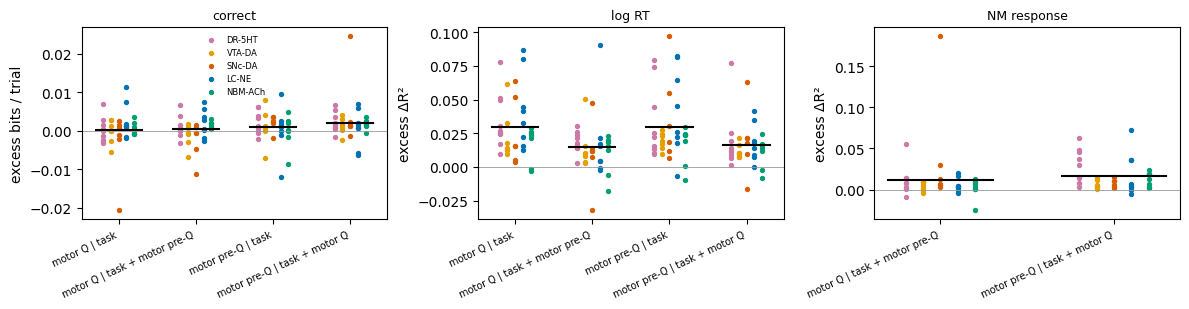

In [8]:
c_tab, c_mice = pp.by_mouse(GS[GS['question'].str.startswith('c.')], group=('question', 'target_NM'))
display(c_tab.pivot_table(index='question', columns='target_NM', values='mean excess')[NM_ORDER].round(4))
display(c_tab.pivot_table(index='question', columns='target_NM', values='p', aggfunc='first')[NM_ORDER].round(3))

QS = [('a.', 'correct'), ('a.', 'log RT'), ('c.', 'NM response')]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, (pre, o) in zip(axes, QS):
    m = (a_mice if pre == 'a.' else c_mice)
    m = m[(m['question'].str.startswith(pre)) & ((m['outcome'] == o) if 'outcome' in m else True)]
    qs = [q for q in sorted(m['question'].unique()) if q != 'c. motor | task']
    for i, q in enumerate(qs):
        for j, nm in enumerate(NM_ORDER):
            v = m[(m['question'] == q) & (m['target_NM'] == nm)]['excess']
            ax.scatter(np.full(len(v), i + (j - 2) * 0.1), v, s=8, color=NM_COLORS[nm], label=nm if i == 0 else None)
        ax.plot([i - .3, i + .3], [m[m['question'] == q]['excess'].mean()] * 2, c='k')
    ax.axhline(0, c='0.6', lw=0.6)
    ax.set_xticks(range(len(qs)), [q.split(' ', 1)[1] for q in qs], rotation=25, fontsize=7, ha='right')
    ax.set_title(f'{o}', fontsize=9); ax.set_ylabel('excess ' + ('bits / trial' if o == 'correct' else 'ΔR²'))
axes[0].legend(fontsize=6, frameon=False)
fig.tight_layout()

**Reading (split).**
- **RT is predicted by both windows, each beyond the other** (unique ΔR² ≈ 0.015 each, 32–34/37 mice). The predictors differ by window:
  - Q: whisking during quiescence → slower (30/36).
  - pre-Q: restlessness (quiescence resets) → slower (34/36); licking before quiescence → faster (only 3/36 positive).
- **Accuracy:** only pre-Q motor adds, and only beyond Q (0.002 bits/trial, p = 0.009, 31/37). Motor state during quiescence says nothing about accuracy.
- **NM baseline → outcome:**
  - DA → lower accuracy is in both windows. VTA-DA Q: p < 0.001; pre-Q: p = 0.04. The β is negative in both (0/7 and 1/7 positive). SNc-DA is negative in Q (0/6), though not significant on its own.
  - DA → slower RT, and 5HT → faster RT, sit in the **quiescence** baseline. Q β: SNc +0.09 (6/6), VTA +0.06 (7/7), 5HT −0.03 (0/9). Pre-Q β is near 0.
  - NBM-ACh Q baseline → lower accuracy (p = 0.03, β positive in 2/7).
- **Motor → NM stimulus response comes from pre-Q, not Q** (5HT p = 0.003, VTA 0.01, SNc 0.02, ACh 0.008; Q beyond pre-Q n.s.). Movement just before the stimulus would be the one to carry over into the response window, so this speaks against simple carry-over. Restlessness earlier in the trial goes with a different stimulus response, with both baselines held fixed.

**So:** the NM signal that predicts the upcoming RT is the one during quiescence, when the wheel is still, and it adds beyond paw/whisk/lick in the same window. That fits a covert readiness or arousal state. For the stimulus response, the relevant behaviour is how restless the mouse was before quiescence.